# IPL Match Winner Prediction

Predict whether the **team batting first** wins an IPL match, using only what is known at the **end of the first innings**: the score, the wickets lost, the two teams and the venue.

**Model:** Logistic Regression · **Data:** IPL 2008–2026 matches (Kaggle) · **Course:** AI101, IIT Ropar

## 1. Load the data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import defaultdict

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, mean_squared_error,
                             mean_absolute_error, log_loss)

np.random.seed(42)
df = pd.read_csv("data/matches.csv")
print("Rows, columns:", df.shape)
df.head()

Rows, columns: (1243, 31)


,event_name,season,match_number,date,city,venue,team1,team2,toss_winner,toss_decision,team1_runs,team1_wickets,team2_runs,team2_wickets,winner,result_type,win_by_runs,win_by_wickets,player_of_match,match_referee,umpire1,umpire2,tv_umpire,reserve_umpire,match_type,overs_limit,balls_per_over,gender,team_type,team1_players,team2_players
0,Indian Premier League,2007/08,1.0,18-04-2008,Bangalore,M Chinnaswamy Stadium,Royal Challengers Bangalore,Kolkata Knight Riders,Royal Challengers Bangalore,field,82,10,222,3,Kolkata Knight Riders,complete,140,0,BB McCullum,J Srinath,Asad Rauf,RE Koertzen,AM Saheba,VN Kulkarni,T20,20,6,male,club,"R Dravid, W Jaffer, V Kohli, JH Kallis, CL Whi...","SC Ganguly, BB McCullum, RT Ponting, DJ Hussey..."
1,Indian Premier League,2007/08,2.0,19-04-2008,Chandigarh,"Punjab Cricket Association Stadium, Mohali",Kings XI Punjab,Chennai Super Kings,Chennai Super Kings,bat,207,4,240,5,Chennai Super Kings,complete,33,0,MEK Hussey,S Venkataraghavan,MR Benson,SL Shastri,RB Tiffin,MSS Ranawat,T20,20,6,male,club,"K Goel, JR Hopes, KC Sangakkara, Yuvraj Singh,...","PA Patel, ML Hayden, MEK Hussey, MS Dhoni, SK ..."
2,Indian Premier League,2007/08,3.0,19-04-2008,Delhi,Feroz Shah Kotla,Delhi Daredevils,Rajasthan Royals,Rajasthan Royals,bat,132,1,129,8,Delhi Daredevils,complete,0,9,MF Maharoof,GR Viswanath,Aleem Dar,GA Pratapkumar,IL Howell,Unknown,T20,20,6,male,club,"G Gambhir, V Sehwag, S Dhawan, MK Tiwary, KD K...","T Kohli, YK Pathan, SR Watson, M Kaif, DS Lehm..."
3,Indian Premier League,2007/08,4.0,20-04-2008,Kolkata,Eden Gardens,Kolkata Knight Riders,Deccan Chargers,Deccan Chargers,bat,112,5,110,10,Kolkata Knight Riders,complete,0,5,DJ Hussey,FM Engineer,BF Bowden,K Hariharan,Asad Rauf,F Gomes,T20,20,6,male,club,"WP Saha, BB McCullum, RT Ponting, SC Ganguly, ...","AC Gilchrist, Y Venugopal Rao, VVS Laxman, A S..."
4,Indian Premier League,2007/08,5.0,20-04-2008,Mumbai,Wankhede Stadium,Mumbai Indians,Royal Challengers Bangalore,Mumbai Indians,bat,165,7,166,5,Royal Challengers Bangalore,complete,0,5,MV Boucher,J Srinath,SJ Davis,DJ Harper,AV Jayaprakash,SN Bandekar,T20,20,6,male,club,"L Ronchi, ST Jayasuriya, DJ Thornely, RV Uthap...","S Chanderpaul, R Dravid, LRPL Taylor, JH Kalli..."


## 2. Explore the data

In [2]:
print("Dataset dimensions:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and missing-value overview:")
df.info()

print("\nSummary of numeric columns:")
display(df.describe())

Dataset dimensions: (1243, 31)

Column names:
['event_name', 'season', 'match_number', 'date', 'city', 'venue', 'team1', 'team2', 'toss_winner', 'toss_decision', 'team1_runs', 'team1_wickets', 'team2_runs', 'team2_wickets', 'winner', 'result_type', 'win_by_runs', 'win_by_wickets', 'player_of_match', 'match_referee', 'umpire1', 'umpire2', 'tv_umpire', 'reserve_umpire', 'match_type', 'overs_limit', 'balls_per_over', 'gender', 'team_type', 'team1_players', 'team2_players']

Data types and missing-value overview:
<class 'pandas.DataFrame'>
RangeIndex: 1243 entries, 0 to 1242
Data columns (total 31 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   event_name       1243 non-null   str    
 1   season           1243 non-null   str    
 2   match_number     1169 non-null   float64
 3   date             1243 non-null   str    
 4   city             1243 non-null   str    
 5   venue            1243 non-null   str    
 6   team1           

,match_number,team1_runs,team1_wickets,team2_runs,team2_wickets,win_by_runs,win_by_wickets,overs_limit,balls_per_over
count,1169.000000,1243.000000,1243.000000,1243.000000,1243.000000,1243.000000,1243.000000,1243.0,1243.0
mean,31.921300,165.851167,5.956557,157.349155,5.873693,13.932422,3.276750,20.0,6.0
std,18.626023,35.490847,2.309341,34.613073,2.646538,23.861556,3.358216,0.0,0.0
min,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,20.0,6.0
25%,16.000000,144.000000,4.000000,138.000000,4.000000,0.000000,0.000000,20.0,6.0
50%,32.000000,165.000000,6.000000,160.000000,6.000000,0.000000,3.000000,20.0,6.0
75%,47.000000,189.000000,8.000000,179.000000,8.000000,20.000000,6.000000,20.0,6.0
max,72.000000,287.000000,10.000000,265.000000,12.000000,146.000000,10.000000,20.0,6.0


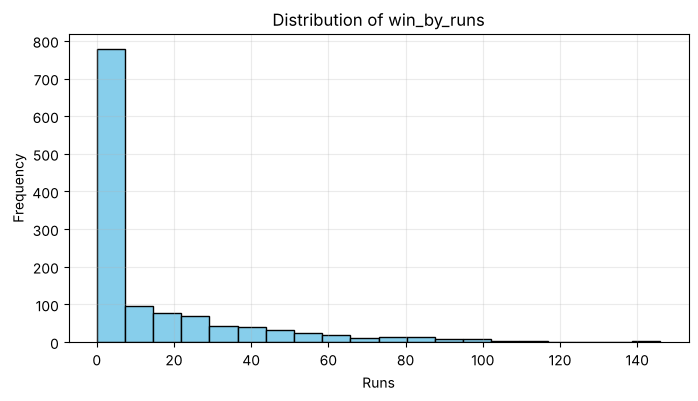

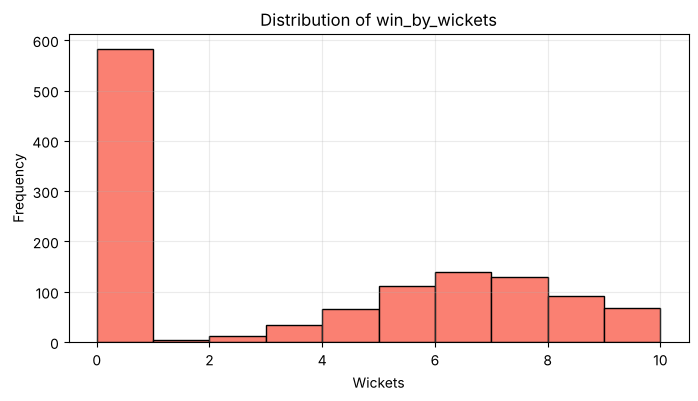

In [3]:
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()

column_to_plot_1 = "win_by_runs"

plt.figure(figsize=(8, 4))
plt.hist(df[column_to_plot_1].dropna(), bins=20, edgecolor="black", color="skyblue")
plt.title(f"Distribution of {column_to_plot_1}")
plt.xlabel("Runs")
plt.ylabel("Frequency")
plt.grid(alpha=0.25)
plt.show()

column_to_plot_2 = "win_by_wickets"

plt.figure(figsize=(8, 4))
plt.hist(df[column_to_plot_2].dropna(), bins=10, edgecolor="black", color="salmon")
plt.title(f"Distribution of {column_to_plot_2}")
plt.xlabel("Wickets")
plt.ylabel("Frequency")
plt.grid(alpha=0.25)
plt.show()

## 3. Clean the data and build features

- Merge renamed franchises and drop matches with no winner
- Work out who batted first from the toss winner and toss decision
- Features: first-innings runs, wickets, runs compared with the average of the previous 60 matches
- Target: `bat_first_won` (1 = batting-first team won, 0 = chasing team won)

In [4]:
# Merge franchises that changed their names, so each team is one category
df = df.replace({"Delhi Daredevils": "Delhi Capitals", "Kings XI Punjab": "Punjab Kings",
                 "Royal Challengers Bangalore": "Royal Challengers Bengaluru",
                 "Rising Pune Supergiants": "Rising Pune Supergiant"})

df = df[(df["winner"] == df["team1"]) | (df["winner"] == df["team2"])].copy()
df["date"] = pd.to_datetime(df["date"], dayfirst=True)
df = df.sort_values("date").reset_index(drop=True)
df["venue"] = df["venue"].str.split(",").str[0]          # "Wankhede Stadium, Mumbai" -> "Wankhede Stadium"
print("Matches after cleaning:", len(df))


other_team = np.where(df["toss_winner"] == df["team1"], df["team2"], df["team1"])
df["bat_first"] = np.where(df["toss_decision"] == "bat", df["toss_winner"], other_team)
df["chase"] = np.where(df["bat_first"] == df["team1"], df["team2"], df["team1"])

bat_first_is_team1 = df["bat_first"] == df["team1"]
df["target_runs"] = np.where(bat_first_is_team1, df["team1_runs"], df["team2_runs"])
df["target_wkts"] = np.where(bat_first_is_team1, df["team1_wickets"], df["team2_wickets"])

# Feature: runs compared with the average of the previous 60 matches (shift(1) = only past matches)
avg_before = df["target_runs"].shift(1).rolling(60, min_periods=10).mean().fillna(160)
df["runs_vs_avg"] = df["target_runs"] - avg_before

# Target: 1 if the team batting first won
df["bat_first_won"] = (df["winner"] == df["bat_first"]).astype(int)

# The numeric feature columns (used for correlation, normalization and the model)
numeric = ["target_runs", "target_wkts", "runs_vs_avg"]
df[["date", "bat_first", "chase", "target_runs", "target_wkts", "runs_vs_avg", "bat_first_won"]].head()

Matches after cleaning: 1218


,date,bat_first,chase,target_runs,target_wkts,runs_vs_avg,bat_first_won
0,2008-04-18,Kolkata Knight Riders,Royal Challengers Bengaluru,222,3,62.0,1
1,2008-04-19,Chennai Super Kings,Punjab Kings,240,5,80.0,1
2,2008-04-19,Rajasthan Royals,Delhi Capitals,129,8,-31.0,0
3,2008-04-20,Deccan Chargers,Kolkata Knight Riders,110,10,-50.0,0
4,2008-04-20,Mumbai Indians,Royal Challengers Bengaluru,165,7,5.0,0


## 4. One-hot encode and split by time

The oldest 80% of matches are used for training and the newest 20% for testing, so the model never sees future matches.

In [5]:

numeric = ["target_runs", "target_wkts", "runs_vs_avg"]
X = pd.get_dummies(df[numeric + ["bat_first", "chase", "venue"]], columns=["bat_first", "chase", "venue"], dtype=int)
y = df["bat_first_won"]

split = int(len(df) * 0.8)
X_train, X_test = X.iloc[:split].copy(), X.iloc[split:].copy()
y_train, y_test = y.iloc[:split], y.iloc[split:]
print("Training matches:", len(X_train), "| Testing matches:", len(X_test))
print("Number of features:", X.shape[1])

Training matches: 974 | Testing matches: 244
Number of features: 75


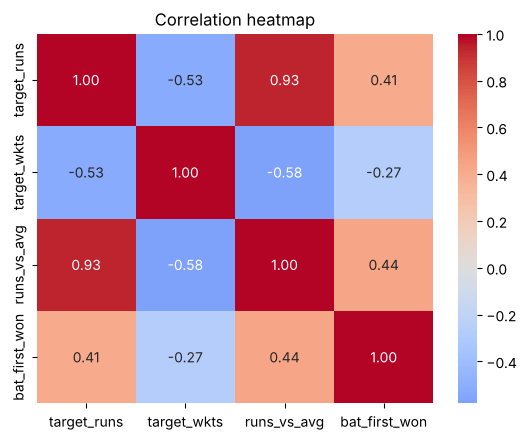

In [6]:
sns.heatmap(df[numeric + ["bat_first_won"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap")
plt.show()

## 5. Scale and select features

`StandardScaler` and `SelectKBest` are fitted on the training data only.

In [7]:
scaler = StandardScaler()
X_train[numeric] = scaler.fit_transform(X_train[numeric])
X_test[numeric] = scaler.transform(X_test[numeric])

# Remove columns that never appear in the training matches (e.g. grounds used only later)
X_train = X_train.loc[:, X_train.std() > 0]
X_test = X_test[X_train.columns]

all_train_columns = X_train.columns   # remembered so new matches can be lined up the same way

# Feature selection: keep the 15 best features
selector = SelectKBest(f_classif, k=15).fit(X_train, y_train)
selected = X_train.columns[selector.get_support()]
X_train, X_test = X_train[selected], X_test[selected]

print("Selected features:", list(selected))

Selected features: ['target_runs', 'target_wkts', 'runs_vs_avg', 'bat_first_Chennai Super Kings', 'bat_first_Gujarat Lions', 'bat_first_Lucknow Super Giants', 'bat_first_Mumbai Indians', 'chase_Chennai Super Kings', 'chase_Deccan Chargers', 'chase_Gujarat Lions', 'chase_Gujarat Titans', 'chase_Pune Warriors', 'venue_Green Park', 'venue_Holkar Cricket Stadium', 'venue_MA Chidambaram Stadium']


## 6. Train and evaluate the model

In [8]:
def train_model(X_tr, y_tr):
    """Train a Logistic Regression model (C=0.1 keeps the model simple)."""
    model = LogisticRegression(C=0.1, max_iter=1000)       # C=0.1: stronger regularization to avoid overfitting
    model.fit(X_tr, y_tr)
    return model

def test_model(model, X_te, y_te):
    """Predict on test data and calculate all the metrics."""
    pred = model.predict(X_te)                      # predicted class (0 or 1)
    prob = model.predict_proba(X_te)[:, 1]          # predicted probability that the batting team wins
    return {"pred": pred,
            "Accuracy": accuracy_score(y_te, pred),
            "Precision": precision_score(y_te, pred),
            "Recall": recall_score(y_te, pred),
            "F1": f1_score(y_te, pred),
            "MSE": mean_squared_error(y_te, prob),
            "MAE": mean_absolute_error(y_te, prob),
            "RMSE": np.sqrt(mean_squared_error(y_te, prob))}

model = train_model(X_train, y_train)
res = test_model(model, X_test, y_test)
print("Model trained. Test accuracy:", round(res["Accuracy"], 3))

Model trained. Test accuracy: 0.684


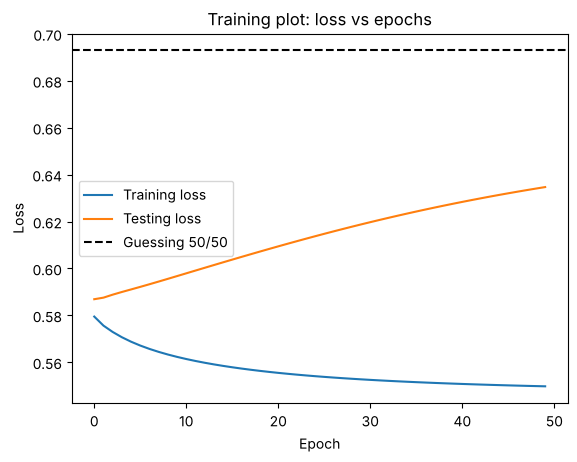

In [9]:
sgd = SGDClassifier(loss="log_loss", learning_rate="constant", eta0=0.01, alpha=1e-3, random_state=42)
train_loss, test_loss = [], []

for epoch in range(50):
    sgd.partial_fit(X_train, y_train, classes=[0, 1])           # one epoch of training
    train_loss.append(log_loss(y_train, sgd.predict_proba(X_train)[:, 1]))
    test_loss.append(log_loss(y_test, sgd.predict_proba(X_test)[:, 1]))

plt.plot(train_loss, label="Training loss")
plt.plot(test_loss, label="Testing loss")
plt.axhline(0.693, color="black", linestyle="--", label="Guessing 50/50")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("Training plot: loss vs epochs")
plt.legend()
plt.show()

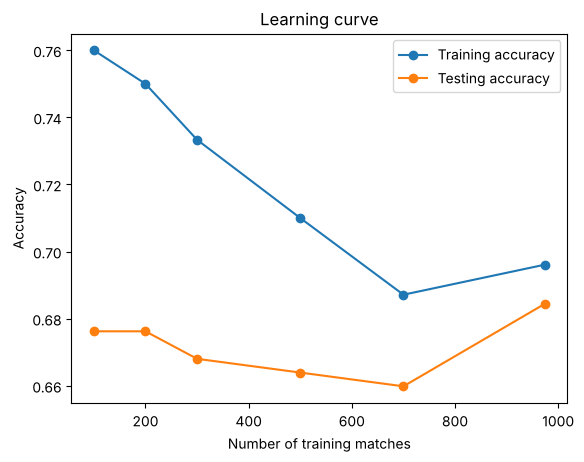

In [10]:
sizes = [100, 200, 300, 500, 700, len(X_train)]
train_acc, test_acc = [], []

for n in sizes:
    m = train_model(X_train.iloc[:n], y_train.iloc[:n])
    train_acc.append(accuracy_score(y_train.iloc[:n], m.predict(X_train.iloc[:n])))
    test_acc.append(accuracy_score(y_test, m.predict(X_test)))

plt.plot(sizes, train_acc, marker="o", label="Training accuracy")
plt.plot(sizes, test_acc, marker="o", label="Testing accuracy")
plt.xlabel("Number of training matches"); plt.ylabel("Accuracy"); plt.title("Learning curve")
plt.legend()
plt.show()

In [11]:
baseline = accuracy_score(y_test, [round(y_train.mean())] * len(y_test))
print("Baseline accuracy (always predict the same team type):", round(baseline, 3), "\n")

metrics = ["Accuracy", "Precision", "Recall", "F1", "MSE", "MAE", "RMSE"]
pd.DataFrame({"Metric": metrics, "Value": [res[m] for m in metrics]}).round(3)

Baseline accuracy (always predict the same team type): 0.545 



,Metric,Value
0,Accuracy,0.684
1,Precision,0.615
2,Recall,0.820
3,F1,0.703
4,MSE,0.207
5,MAE,0.394
6,RMSE,0.455


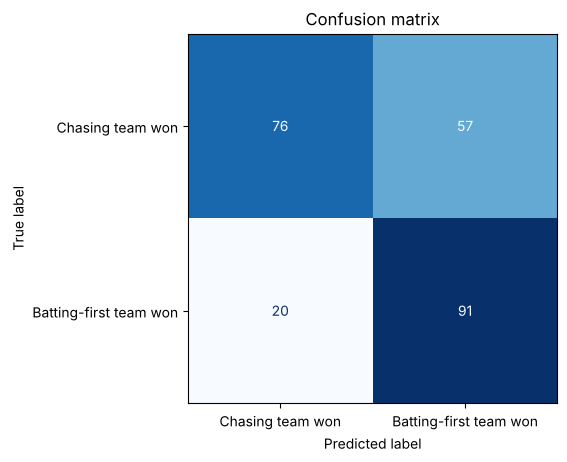

In [12]:
ConfusionMatrixDisplay(confusion_matrix(y_test, res["pred"]),
                       display_labels=["Chasing team won", "Batting-first team won"]).plot(cmap="Blues", colorbar=False)
plt.title("Confusion matrix")
plt.show()

In [13]:
from sklearn.metrics import roc_auc_score, classification_report

print("Detailed classification report:")
print(classification_report(
    y_test, res["pred"],
    target_names=["Chasing team won", "Batting-first team won"],
    zero_division=0
))

if y_test.nunique() == 2:
    print("ROC-AUC:", round(roc_auc_score(y_test, model.predict_proba(X_test)[:, 1]), 3))
else:
    print("ROC-AUC cannot be calculated because the test set contains only one class.")

Detailed classification report:
                        precision    recall  f1-score   support

      Chasing team won       0.79      0.57      0.66       133
Batting-first team won       0.61      0.82      0.70       111

              accuracy                           0.68       244
             macro avg       0.70      0.70      0.68       244
          weighted avg       0.71      0.68      0.68       244

ROC-AUC: 0.767


## 7. Predict a new match

In [14]:
def predict_ipl_winner(batting_first_team, chasing_team, venue,
                       first_innings_runs, first_innings_wickets):
    if batting_first_team == chasing_team:
        raise ValueError("The two teams must be different.")
    if not 0 <= int(first_innings_wickets) <= 10:
        raise ValueError("Wickets must be between 0 and 10.")
    if float(first_innings_runs) < 0:
        raise ValueError("Runs cannot be negative.")

    recent_average = df["target_runs"].iloc[:split].tail(60).mean()
    if pd.isna(recent_average):
        recent_average = 160.0

    aliases = {
        "Delhi Daredevils": "Delhi Capitals",
        "Kings XI Punjab": "Punjab Kings",
        "Royal Challengers Bangalore": "Royal Challengers Bengaluru",
        "Rising Pune Supergiants": "Rising Pune Supergiant"
    }
    batting_first_team = aliases.get(batting_first_team, batting_first_team)
    chasing_team = aliases.get(chasing_team, chasing_team)
    venue = str(venue).split(",")[0].strip()

    new_match = pd.DataFrame([{
        "target_runs": float(first_innings_runs),
        "target_wkts": float(first_innings_wickets),
        "runs_vs_avg": float(first_innings_runs) - float(recent_average),
        "bat_first": batting_first_team,
        "chase": chasing_team,
        "venue": venue
    }])

    new_match = pd.get_dummies(
        new_match, columns=["bat_first", "chase", "venue"], dtype=int
    )

    # Line the new match up with the training columns, scale it the same way,
    # then keep the same 15 selected features the model was trained on
    new_match = new_match.reindex(columns=all_train_columns, fill_value=0)
    new_match[numeric] = scaler.transform(new_match[numeric])
    new_match = new_match[selected]

    batting_first_probability = model.predict_proba(new_match)[0, 1]
    chasing_probability = 1 - batting_first_probability

    predicted_winner = (
        batting_first_team if batting_first_probability >= 0.5 else chasing_team
    )

    print("Predicted winner:", predicted_winner)
    print(f"{batting_first_team} win probability: {batting_first_probability:.1%}")
    print(f"{chasing_team} win probability: {chasing_probability:.1%}")

    return predicted_winner


predicted_winner = predict_ipl_winner(
    batting_first_team="Chennai Super Kings",
    chasing_team="Mumbai Indians",
    venue="Wankhede Stadium",
    first_innings_runs=185,
    first_innings_wickets=6
)

Predicted winner: Chennai Super Kings
Chennai Super Kings win probability: 56.5%
Mumbai Indians win probability: 43.5%


In [15]:
# Try other first-innings scores for the same match
for runs, wickets in [(220, 4), (140, 8)]:
    print(f"\nChennai Super Kings make {runs}/{wickets}:")
    predict_ipl_winner("Chennai Super Kings", "Mumbai Indians", "Wankhede Stadium", runs, wickets)



Chennai Super Kings make 220/4:
Predicted winner: Chennai Super Kings
Chennai Super Kings win probability: 82.1%
Mumbai Indians win probability: 17.9%

Chennai Super Kings make 140/8:
Predicted winner: Mumbai Indians
Chennai Super Kings win probability: 20.5%
Mumbai Indians win probability: 79.5%


## 8. Interpretation of results

**Problem:** predict whether the team batting first wins an IPL match, using the teams, the venue and the first-innings score and wickets (logistic regression, about 1,200 matches).

**Key findings**

1. **The model beats guessing.** A baseline that always predicts one outcome gets 54.5% accuracy. The model gets 68.4%, about 14 points higher. The first-innings score, the teams and the venue carry real information about who wins.
2. **It leans towards the batting-first team.** Precision is 0.62: when it says "batting-first wins", it is right 62% of the time. Recall is 0.82: it catches 82% of the real batting-first wins. Chasing wins are caught only 57% of the time (76 of 133), so most mistakes are chasing wins labelled as batting-first wins (see the confusion matrix).
3. **It ranks outcomes reasonably well.** ROC-AUC is 0.77: given one match the batting-first team won and one it lost, the model gives the win the higher probability about 77% of the time. F1 is 0.70.
4. **The probabilities are only moderately confident.** RMSE is 0.46 and MAE is 0.39, so the predicted probabilities are better than a coin flip but not sharp.
5. **There is mild overfitting.** In the training plot, training loss falls while testing loss rises slightly. Test loss stays below 0.693 (the coin-flip level), so the model still beats guessing. Strong regularisation (C=0.1) limits the overfitting.
6. **The predictions make cricket sense.** For CSK batting first against MI at Wankhede, 140/8 gives CSK about 20%, 185/6 about 56% and 220/4 about 82%.

**Conclusion:** the model predicts the winner of an IPL match with about 68% accuracy after the first innings. That is clearly better than guessing but not highly reliable, because cricket has a lot of randomness, especially during the chase.
